# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Student:** Gyan Bahadur Tamang  
**Course:** MSCS 634 — Big Data and Data Mining  
**Assignment:** Lab 5  

This notebook applies Agglomerative Hierarchical Clustering and DBSCAN to scikit-learn's Wine Dataset.

## Environment Setup

Run this cell first. Restart the kernel if packages are newly installed, then choose **Run All**.

In [1]:
%pip install -q pandas numpy matplotlib scipy scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 1: Data Preparation and Exploration

`.head()`, `.info()`, and `.describe()` examine structure and distributions. Standardization is essential because both algorithms use distances and the raw feature scales differ greatly.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage,dendrogram
from sklearn.cluster import AgglomerativeClustering,DBSCAN
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score,homogeneity_score,completeness_score
from sklearn.preprocessing import StandardScaler

wine=load_wine()
X=pd.DataFrame(wine.data,columns=wine.feature_names)
y=pd.Series(wine.target,name='target')
display(X.head())
X.info()
display(X.describe())
print('Class distribution:',y.value_counts().sort_index().to_dict())
print('Missing values:',int(X.isna().sum().sum()))
scaler=StandardScaler(); X_scaled=scaler.fit_transform(X)
print('Scaled means:',np.round(X_scaled.mean(axis=0),6))
print('Scaled standard deviations:',np.round(X_scaled.std(axis=0),6))
pca=PCA(n_components=2); X_pca=pca.fit_transform(X_scaled)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


Class distribution: {0: 59, 1: 71, 2: 48}
Missing values: 0
Scaled means: [-0. -0. -0. -0. -0.  0. -0.  0. -0.  0.  0.  0. -0.]
Scaled standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Step 2: Hierarchical Clustering

### 1. Test Different Numbers of Clusters

Ward linkage is evaluated for 2–5 clusters. Metrics against known classes are included for interpretation, although clustering itself does not use those labels.

In [3]:
hierarchical_rows=[]; hierarchical_labels={}
for n_clusters in [2,3,4,5]:
    labels=AgglomerativeClustering(n_clusters=n_clusters,linkage='ward').fit_predict(X_scaled)
    hierarchical_labels[n_clusters]=labels
    hierarchical_rows.append({'n_clusters':n_clusters,'Silhouette':silhouette_score(X_scaled,labels),'Homogeneity':homogeneity_score(y,labels),'Completeness':completeness_score(y,labels)})
hierarchical_results=pd.DataFrame(hierarchical_rows)
hierarchical_results

,n_clusters,Silhouette,Homogeneity,Completeness
0,2,0.267013,0.444094,0.774489
1,3,0.277444,0.790429,0.782541
2,4,0.225837,0.790429,0.649028
3,5,0.186742,0.810589,0.576247


### 2. Visualize the Hierarchical Clusters

The model uses all 13 standardized features; PCA supplies only the two-dimensional view. Three clusters give the best tested Silhouette Score.

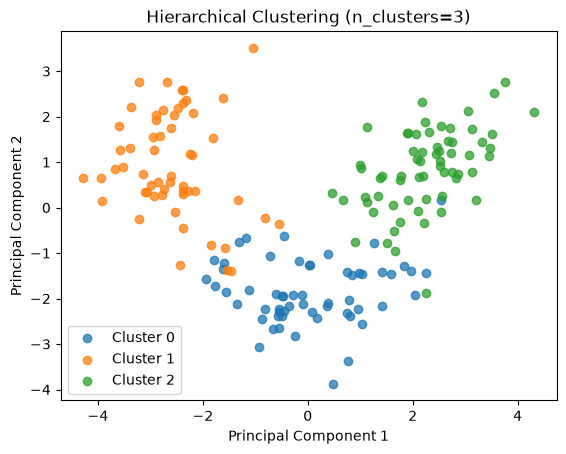

In [4]:
labels=hierarchical_labels[3]
for label in np.unique(labels):
    mask=labels==label
    plt.scatter(X_pca[mask,0],X_pca[mask,1],label=f'Cluster {label}',alpha=.75)
plt.title('Hierarchical Clustering (n_clusters=3)'); plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2'); plt.legend(); plt.show()

### 3. Dendrogram and Interpretation

The Ward dendrogram shows the progressive merging of observations. Long vertical gaps near the upper merges indicate comparatively strong separation. A horizontal cut before the final major merges yields a small number of broad groups, supporting approximately three clusters. The plot is truncated to the last 30 merged groups for readability; parenthetical labels show contracted sample counts.

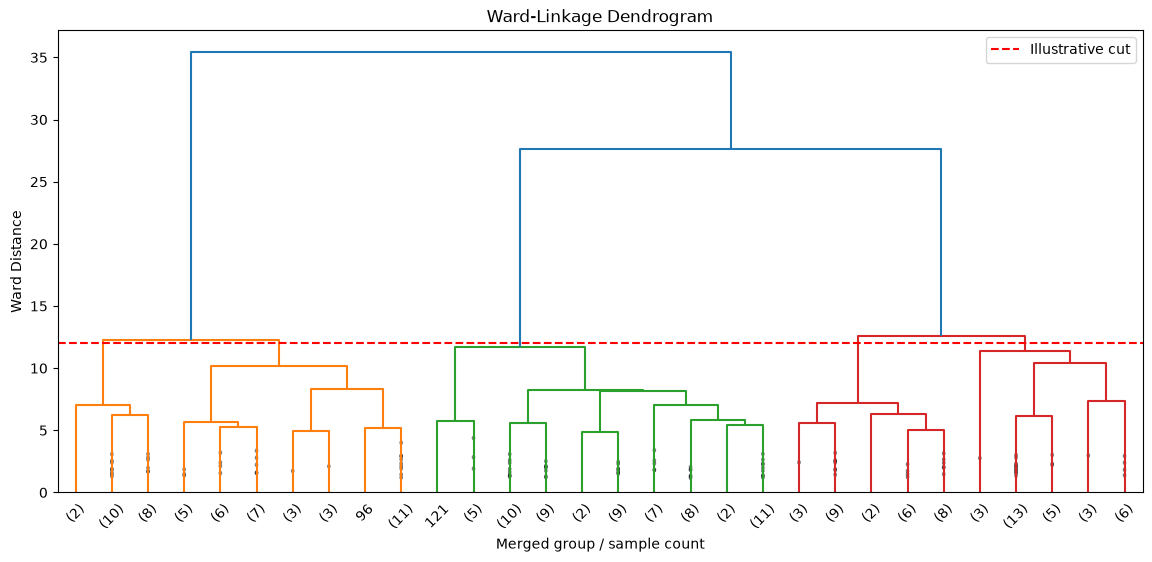

In [5]:
linked=linkage(X_scaled,method='ward')
plt.figure(figsize=(14,6))
dendrogram(linked,truncate_mode='lastp',p=30,leaf_rotation=45,show_contracted=True)
plt.axhline(y=12,color='red',linestyle='--',label='Illustrative cut')
plt.title('Ward-Linkage Dendrogram'); plt.xlabel('Merged group / sample count'); plt.ylabel('Ward Distance'); plt.legend(); plt.show()

## Step 3: DBSCAN Clustering

### 1. Parameter Experiments

Small eps values produce many tiny clusters and many noise points. Larger values connect most observations into one cluster, making Silhouette undefined. Increasing `min_samples` makes the density requirement stricter and generally increases noise or merging behavior.

In [6]:
settings=[(1.5,3),(2.0,3),(2.5,3),(2.5,5),(3.0,3),(3.0,5),(3.5,5),(4.0,5)]
dbscan_rows=[]; dbscan_labels={}
for eps,min_samples in settings:
    labels=DBSCAN(eps=eps,min_samples=min_samples).fit_predict(X_scaled)
    dbscan_labels[(eps,min_samples)]=labels
    mask=labels!=-1
    n_clusters=len(set(labels))-(1 if -1 in labels else 0)
    sil=silhouette_score(X_scaled[mask],labels[mask]) if n_clusters>=2 and mask.sum()>n_clusters else np.nan
    dbscan_rows.append({'eps':eps,'min_samples':min_samples,'Clusters':n_clusters,'Noise Points':(labels==-1).sum(),'Silhouette':sil,'Homogeneity':homogeneity_score(y,labels),'Completeness':completeness_score(y,labels)})
dbscan_results=pd.DataFrame(dbscan_rows)
dbscan_results

,eps,min_samples,Clusters,Noise Points,Silhouette,Homogeneity,Completeness
0,1.5,3,8,147,0.331067,0.189179,0.251015
1,2.0,3,5,64,0.211348,0.442287,0.372380
2,2.5,3,1,23,NaN,0.066807,0.188510
3,2.5,5,1,24,NaN,0.057588,0.158148
4,3.0,3,2,7,0.239187,0.031093,0.134726
5,3.0,5,1,11,NaN,0.030877,0.144610
6,3.5,5,1,6,NaN,0.029348,0.216227
7,4.0,5,1,3,NaN,0.014464,0.183668


### 2. Selected DBSCAN Metrics

`eps=2.0, min_samples=3` is selected as a compromise: it retains several density-based groups and visibly identifies noise. Silhouette is calculated only among non-noise observations because label −1 means unassigned noise; homogeneity and completeness retain −1 to evaluate the entire output.

In [7]:
selected_labels=dbscan_labels[(2.0,3)]
mask=selected_labels!=-1
print('Clusters:',len(set(selected_labels))-1)
print('Noise points:',int((selected_labels==-1).sum()))
print(f'Silhouette Score: {silhouette_score(X_scaled[mask],selected_labels[mask]):.4f}')
print(f'Homogeneity Score: {homogeneity_score(y,selected_labels):.4f}')
print(f'Completeness Score: {completeness_score(y,selected_labels):.4f}')

Clusters: 5
Noise points: 64
Silhouette Score: 0.2113
Homogeneity Score: 0.4423
Completeness Score: 0.3724


### 3. DBSCAN Visualization with Noise

Black X markers are observations DBSCAN labels as noise. PCA again provides only the visualization; DBSCAN operates in the full standardized feature space.

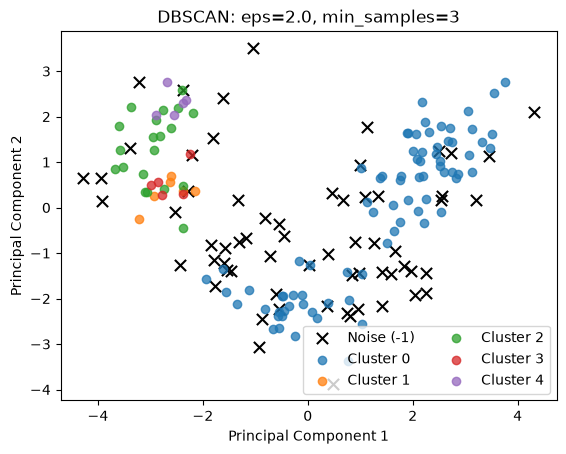

In [8]:
for label in np.unique(selected_labels):
    mask=selected_labels==label
    if label==-1:
        plt.scatter(X_pca[mask,0],X_pca[mask,1],c='black',marker='x',s=65,label='Noise (-1)')
    else:
        plt.scatter(X_pca[mask,0],X_pca[mask,1],alpha=.75,label=f'Cluster {label}')
plt.title('DBSCAN: eps=2.0, min_samples=3'); plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2'); plt.legend(ncol=2); plt.show()

## Step 4: Analysis and Insights

### 1. Comparison

Hierarchical clustering with three clusters performs better for this dataset: Silhouette **0.2774**, Homogeneity **0.7904**, and Completeness **0.7825**. Selected DBSCAN achieves Silhouette **0.2113** on non-noise points, Homogeneity **0.4423**, and Completeness **0.3724**, while labeling 64 observations as noise.

### 2. Parameter Influence

For hierarchical clustering, moving from two to three clusters improves separation and class agreement; four or five clusters fragment natural groups and reduce Silhouette. For DBSCAN, low eps is too restrictive and produces extensive noise, while high eps joins observations into one broad cluster. Raising `min_samples` increases the density evidence required for core points.

### 3. Strengths and Weaknesses

- **Hierarchical clustering** provides a dendrogram, does not require centroid initialization, and works well for this compact dataset. Its disadvantages are computational cost on large datasets, sensitivity to linkage/distance choices, and the inability to revise early merges.
- **DBSCAN** can find irregular shapes and explicitly detect noise without specifying the number of clusters. Its weaknesses are sensitivity to eps and min_samples, difficulty with varying densities, and degraded distance contrast in high-dimensional data.

### Conclusion

The standardized Wine data contains broad compact groups that Ward hierarchical clustering captures well. DBSCAN reveals possible noise but does not recover the known class structure as effectively under the tested full-dimensional settings.